# d = 16 Gaussian test: when can we trust D_k, and how does it compare with the exact value?

We draw signals from a Gaussian whose properties we know exactly, fit the model, and check what it says about each *group* of statistics.

**Words used**
- **D_k** = KL(p ‖ q_k): how much the model changes if the energy of group k is removed **without refitting** the other terms (nats). Large = the group matters.
- **I_k** = S(q_k*) − S(p): the entropy gained by the group, i.e. the same removal **with refitting** of the remaining terms. Always I_k ≤ D_k.
- **D̂_k**: our estimate of D_k from 10⁴ generated signals. On average over independent sample sets it is a lower bound of D_k (Jensen); a single run can fall above D_k by fluctuation.
- **ESS** (effective sample size): how many signals really contribute to the estimate. ≈ 10⁴ is good, ≈ 1 is bad.
- **k̂**: tail shape of the weights e^A. If k̂ > 0.5, the average cannot be trusted.
- **z**: for a Scat2 group, z = 1 means q_k is not normalisable (D_k = ∞). We also give **1 − z**, computed without cancellation: in float64 the difference 1 − z is lost when z is within 1e-16 of 1. This happened to the low-pass term in the earlier version of this notebook, which wrongly reported D_k = ∞ for it (its exact D_k is 38.7 nats).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
%matplotlib inline

RUN = Path('../runs/d16/results')    # outputs of the d16 run
RES = Path('results')                # exact-bench tables (run_bench.py, kl_reverse.py)
sys.path.insert(0, '../../kl_groups')
import plots as P

BLUE, ORANGE, AQUA, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6})
spec = torch.load(RUN / 'spectrum.pt', map_location='cpu', weights_only=False)
check = pd.read_csv(RUN / 'check.csv')
bench = pd.read_csv(RES / 'bench_exact_D.csv', dtype={'terms': str})
rkl = pd.read_csv(RES / 'reverse_KL.csv', dtype={'terms': str})
c900 = pd.read_csv(RES / 'compare_scat2_Dk_seed900.csv', dtype={'terms': str})
cseed = pd.read_csv(RES / 'compare_scat2_Dk_seeds.csv', dtype={'terms': str})
csens = pd.read_csv(RES / 'compare_scat2_Dk_sensitivity.csv')
cIk = pd.read_csv(RES / 'compare_scat2_Dk_Ik.csv', dtype={'terms': str})

## 0. Why this Gaussian is not white noise (three pictures)
**Precision** = 1 / variance at a frequency. A Gaussian is fixed by its 9 variances (frequencies 0…8 of a real signal of length 16).
The Scat2 model does not record these 9 numbers. It records only **5 band energies**, and its precision must be a mix of the **5 filter shapes**.
So the Gaussian that the data come from is the closest one the model can describe, not white noise.

In [2]:
S = spec['S'][0].double().numpy(); M = int(spec['M']); NM = M // 2 + 1
psi2 = spec['psi2'].double().numpy()            # (5, M): |filter_l(w)|^2, l = 0 finest ... 4 low-pass
g = np.array([[2 * psi2[l, w] if w in (0, M // 2) else psi2[l, w] + psi2[l, M - w] for w in range(NM)] for l in range(5)])   # shape each filter gives to the precision
t, *_ = np.linalg.lstsq(g.T, M / S[:NM], rcond=None)     # weights of our Gaussian: its precision 1/C = sum_l t_l g_l (exact)
COL = [BLUE, ORANGE, AQUA, '#8a5cd0', '#c9a227']
NAMES = ['filter 0 (finest)', 'filter 1', 'filter 2', 'filter 3', 'filter 4 (low-pass)']
w = np.arange(NM)

**A. The 5 filter shapes.** Each curve is one filter, over the frequencies 0…8 (frequencies 0 and 8 count twice: they have no mirror frequency). They overlap, but not evenly.

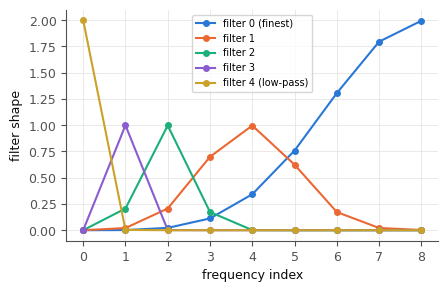

In [3]:
fig, ax = plt.subplots(figsize=(4.8, 3.0))
for l in range(5):
    ax.plot(w, g[l], 'o-', color=COL[l], ms=4, label=NAMES[l])
ax.set_xlabel('frequency index'); ax.set_ylabel('filter shape'); ax.legend(fontsize=7, loc='upper center')
plt.show()

**B. What the model records.** Left: the Fourier description of white noise, 9 numbers. Right: what the 5 Scat2 statistics record, the energy in each band (variance weighted by the filter).

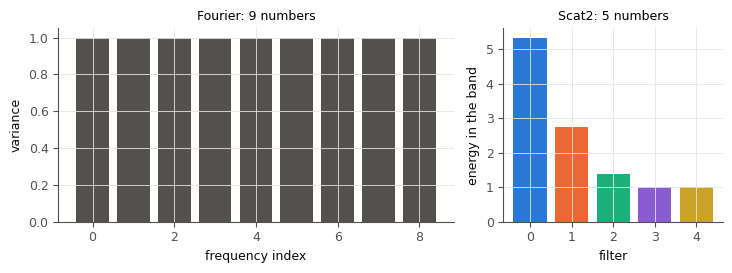

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 2.8), gridspec_kw={'width_ratios': [9, 5]})
axs[0].bar(w, np.ones(NM), color=MUTED); axs[0].set_xlabel('frequency index'); axs[0].set_ylabel('variance'); axs[0].set_title('Fourier: 9 numbers', fontsize=9)
axs[1].bar(range(5), psi2.sum(1), color=COL); axs[1].set_xticks(range(5), ['0', '1', '2', '3', '4']); axs[1].set_xlabel('filter')
axs[1].set_ylabel('energy in the band'); axs[1].set_title('Scat2: 5 numbers', fontsize=9)
plt.tight_layout(); plt.show()

**C. The closest Gaussian.** The bars are the precision of our Gaussian, built from the 5 filter shapes (one colour per filter). White noise would need the dashed flat line. No mix of the 5 shapes is flat, so the best match has ripples.

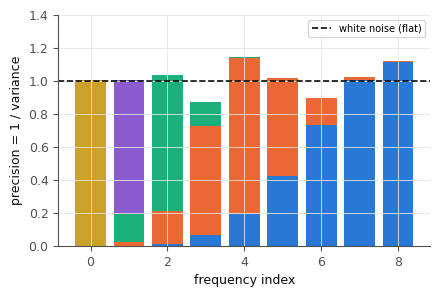

precision of our Gaussian: from 0.87 to 1.14 (white noise: 1). Best possible mix of the 5 shapes for a flat precision: largest deviation 0.14


In [5]:
fig, ax = plt.subplots(figsize=(4.8, 3.0))
bottom = np.zeros(NM)
for l in range(5):
    ax.bar(w, t[l] * g[l], bottom=bottom, color=COL[l], width=0.8); bottom += t[l] * g[l]
ax.axhline(1, color=INK, ls='--', lw=1.2, label='white noise (flat)')
ax.set_xlabel('frequency index'); ax.set_ylabel('precision = 1 / variance'); ax.legend(fontsize=7, loc='upper right'); ax.set_ylim(0, 1.4)
plt.show()
t1, *_ = np.linalg.lstsq(g.T, np.ones(NM), rcond=None)
print(f'precision of our Gaussian: from {bottom.min():.2f} to {bottom.max():.2f} (white noise: 1). Best possible mix of the 5 shapes for a flat precision: largest deviation {np.abs(g.T @ t1 - 1).max():.2f}')

## 1. The data
**What:** Gaussian signals of 16 samples. The plot shows the variance at each frequency; white noise would be the dashed line.
**Model:** 24 statistics: L₆ (5), Scat2 (5), Scat4 Real (10), Scat4 Imag (4). The truth contains **only Scat2**, so the other 19 should get zero weight.
**Why rippled:** 5 Scat2 statistics cannot describe white noise exactly; the ripples (±15 %) are the closest Gaussian they can describe.

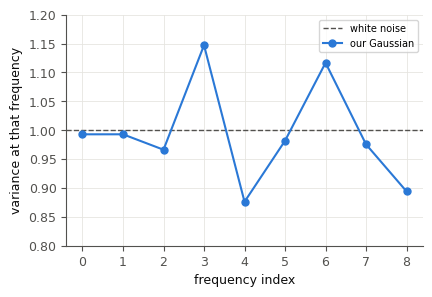

entropy of this Gaussian: 22.6743 nats (white noise: 22.7030)


In [6]:
S = spec['S'][0].double().numpy(); M = int(spec['M']); C = S / M
fig, ax = plt.subplots(figsize=(4.6, 3.0))
ax.axhline(1, color=MUTED, lw=1, ls='--', label='white noise')
ax.plot(np.arange(M // 2 + 1), C[:M // 2 + 1], 'o-', color=BLUE, ms=5, lw=1.5, label='our Gaussian')
ax.set_xlabel('frequency index'); ax.set_ylabel('variance at that frequency'); ax.set_ylim(0.8, 1.2); ax.legend(fontsize=7, loc='upper right')
plt.show()
print(f"entropy of this Gaussian: {spec['H_star']:.4f} nats (white noise: {spec['H_source']:.4f})")

## 2. Does the fitted model recover the truth?
**What:** 5 independent runs (seeds). *bound − exact* is the model's entropy estimate minus the exact entropy: it should be ≈ 0. *θ error* is the error of the fitted Scat2 coefficients.
**Takeaway:** the bound is within 0.03 nats of the exact value and θ within 2.5 %. The fit works.

In [7]:
check.rename(columns={'H_star': 'exact entropy', 'H_bound_1': 'model entropy bound', 'Hbound1_minus_Hstar': 'bound − exact',
                      'theta2_rel_err': 'θ(Scat2) rel. error'})[['seed', 'exact entropy', 'model entropy bound', 'bound − exact', 'θ(Scat2) rel. error']].round(4)

,seed,exact entropy,model entropy bound,bound − exact,θ(Scat2) rel. error
0,900,22.6743,22.6801,0.0057,0.0242
1,901,22.6743,22.6824,0.0081,0.0163
2,902,22.6743,22.6474,-0.0269,0.0198
3,903,22.6743,22.6653,-0.0091,0.0205
4,904,22.6743,22.6689,-0.0054,0.0245


## 3. The extra Scat4 groups: D_k should be ≈ 0
**What:** the true weight of Scat4 is 0, so removing it changes nothing: the true D_k is 0. With finite data the fit gives tiny weights, and their effect on D_k is predicted independently from the fitted weights (black dash).
**Read:** blue dots = D̂ of the 5 seeds, for the whole Real family (10 terms) and the whole Imag family (4 terms).
**Takeaway:** D̂ is of order 10⁻³ nats and within a factor 0.73–1.38 of the prediction. These groups are well measured (ESS ≈ 10⁴), so here D̂ can be trusted.

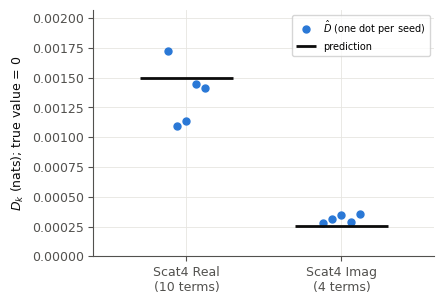

Scat4 Real: D̂ / predicted from 0.73 to 1.15 | smallest ESS = 9963 of 10000
Scat4 Imag: D̂ / predicted from 1.09 to 1.38 | smallest ESS = 9993 of 10000


In [8]:
h = pd.read_csv(RUN / 'H_gauss4.csv'); pr = pd.read_csv(RUN / 'pred_H.csv').set_index('group')
fams = (('fam:Scattering_Fourth_Order_Mod2_Real_Q1', 'Scat4 Real\n(10 terms)'), ('fam:Scattering_Fourth_Order_Mod2_Imag_Q1', 'Scat4 Imag\n(4 terms)'))
fig, ax = plt.subplots(figsize=(4.4, 3.2))
for i, (g, name) in enumerate(fams):
    d = h[h.group == g]
    ax.plot(i + np.linspace(-0.12, 0.12, len(d)), d.H, 'o', color=BLUE, ms=5, label=r'$\hat{D}$ (one dot per seed)' if i == 0 else None)
    ax.hlines(pr.loc[g, 'H_pred'], i - 0.3, i + 0.3, color=INK, lw=2, label='prediction' if i == 0 else None)
ax.set_xticks([0, 1], [n for _, n in fams]); ax.set_xlim(-0.6, 1.6); ax.set_ylim(0, 1.2 * h[h.group.isin([g for g, _ in fams])].H.max())
ax.set_ylabel(r'$D_k$ (nats); true value = 0'); ax.legend(fontsize=7, loc='upper right')
plt.show()
for g, name in fams:
    d = h[h.group == g]; r = d.H / pr.loc[g, 'H_pred']
    print(f"{name.splitlines()[0]}: D̂ / predicted from {r.min():.2f} to {r.max():.2f} | smallest ESS = {(d.ess_frac * d.N).min():.0f} of {int(d.N.iloc[0])}")

In [9]:
h = pd.read_csv(RUN / 'H_gauss4.csv'); pr = pd.read_csv(RUN / 'pred_H.csv').set_index('group')
rows = []
for g, name in (('fam:Scattering_Fourth_Order_Mod2_Real_Q1', 'Scat4 Real (10 terms)'), ('fam:Scattering_Fourth_Order_Mod2_Imag_Q1', 'Scat4 Imag (4 terms)')):
    for _, r in h[h.group == g].iterrows():
        rows.append({'family': name, 'seed': int(r.seed), 'D̂': r.H, 'predicted': pr.loc[g, 'H_pred'], 'ESS (of 10000)': round(r.ess_frac * r.N)})
t = pd.DataFrame(rows); t['D̂ / predicted'] = t['D̂'] / t['predicted']
t.round(5)

,family,seed,D̂,predicted,ESS (of 10000),D̂ / predicted
0,Scat4 Real (10 terms),900,0.00172,0.00150,9963,1.15060
1,Scat4 Real (10 terms),901,0.00109,0.00150,9978,0.72907
2,Scat4 Real (10 terms),902,0.00114,0.00150,9977,0.75901
3,Scat4 Real (10 terms),903,0.00144,0.00150,9969,0.96371
4,Scat4 Real (10 terms),904,0.00141,0.00150,9972,0.94377
5,Scat4 Imag (4 terms),900,0.00028,0.00026,9994,1.09272
6,Scat4 Imag (4 terms),901,0.00031,0.00026,9994,1.21989
7,Scat4 Imag (4 terms),902,0.00034,0.00026,9993,1.33211
8,Scat4 Imag (4 terms),903,0.00029,0.00026,9994,1.12345
9,Scat4 Imag (4 terms),904,0.00035,0.00026,9993,1.37531


## 4. Exact test: when does D̂ fail?
**What:** for the Scat2 statistics D_k can be computed exactly. We remove every combination of the 5 terms (31 groups; label = which terms) and compare with 200 fresh sets of 10⁴ exact draws of p* each.
**Read:** black diamond = exact D_k (triangle at the top = infinite). Blue = our estimate D̂ (bar = spread over sets). x-axis: each position is one way of removing terms; the label lists the removed terms (04 = terms 0 and 4 removed together).
**Takeaway:** 24 of the 31 groups have a finite exact D_k; the other 7 are truly infinite (a Fourier mode is left with no term). The mean D̂ is below the exact D_k in all 24 finite groups (median ratio 0.08). D̂ stays between 0.8 and 7.5 nats for all 31 groups while the exact D_k of the groups containing the low-pass term (term 4) is 38 nats or more.

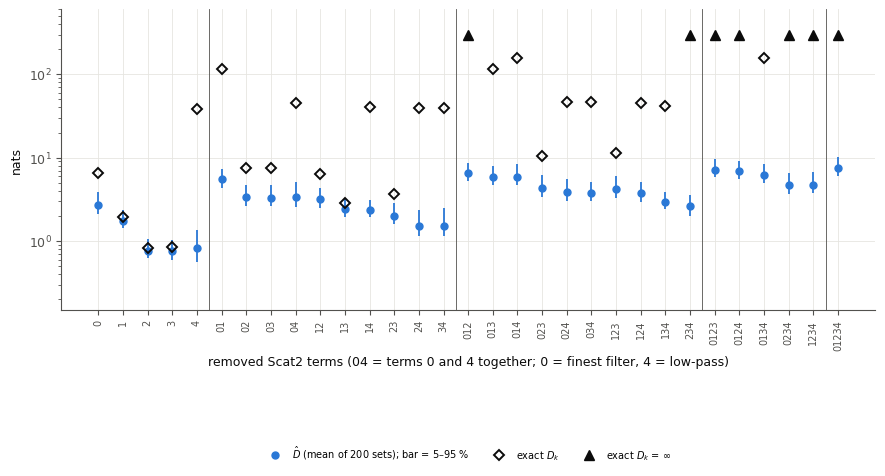

finite exact D_k: 24 of 31 groups | D̂ below exact in 24 of 24 | median D̂/exact = 0.08


In [10]:
d = bench.reset_index(drop=True); x = np.arange(len(d)); TOP = 300
fig, ax = plt.subplots(figsize=(10.5, 3.9))
ax.vlines(x, d.Dhat_q05, d.Dhat_q95, color=BLUE, lw=1.3, zorder=2)
ax.plot(x, d.Dhat_mean, 'o', color=BLUE, ms=5, label=r'$\hat{D}$ (mean of 200 sets); bar = 5–95 %', zorder=3)
fm = np.isfinite(d.D_exact)
ax.plot(x[fm], d.D_exact[fm], 'D', color=INK, ms=5, mfc='none', mew=1.4, label=r'exact $D_k$', zorder=4)
ax.plot(x[~fm], np.full(int((~fm).sum()), TOP), '^', color=INK, ms=7, label=r'exact $D_k$ = ∞', zorder=4)
for s in (4, 14, 24, 29):
    ax.axvline(s + 0.5, color=MUTED, lw=0.6)
ax.set_yscale('log'); ax.set_ylim(0.15, 600); ax.set_xticks(x, d.terms, rotation=90, fontsize=7)
ax.set_xlabel('removed Scat2 terms (04 = terms 0 and 4 together; 0 = finest filter, 4 = low-pass)'); ax.set_ylabel('nats')
ax.legend(fontsize=7, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.42), frameon=False)
plt.show()
fin = d[np.isfinite(d.D_exact)]
print(f"finite exact D_k: {len(fin)} of {len(d)} groups | D̂ below exact in {int((fin.Dhat_mean < fin.D_exact).sum())} of {len(fin)} | "
      f"median D̂/exact = {(fin.Dhat_mean / fin.D_exact).median():.2f}")

In [11]:
inf = d[~np.isfinite(d.D_exact)]
print('groups with exact D_k = inf:', ', '.join(inf.terms), f'({len(inf)} of {len(d)})')
print(f'D̂ (mean over the 200 sets), all {len(d)} groups: from {d.Dhat_mean.min():.2f} to {d.Dhat_mean.max():.2f} nats; exact D_k of the finite groups: from {fin.D_exact.min():.2f} to {fin.D_exact.max():.1f} nats')
print(f"x_min = 1 - z (smallest over the modes) for the finite groups with z within 1e-9 of 1: {int((fin.x_min < 1e-9).sum())} groups; smallest x_min = {fin.x_min.min():.2e}")
print('D̂ / exact D_k, finite groups with exact D_k > ln N = 9.2:', np.round((fin.Dhat_mean / fin.D_exact)[fin.D_exact > np.log(1e4)].values, 3))

groups with exact D_k = inf: 012, 234, 0123, 0124, 0234, 1234, 01234 (7 of 31)
D̂ (mean over the 200 sets), all 31 groups: from 0.76 to 7.46 nats; exact D_k of the finite groups: from 0.83 to 156.2 nats
x_min = 1 - z (smallest over the modes) for the finite groups with z within 1e-9 of 1: 13 groups; smallest x_min = 4.40e-35
D̂ / exact D_k, finite groups with exact D_k > ln N = 9.2: [0.021 0.047 0.074 0.058 0.038 0.038 0.05  0.038 0.417 0.083 0.081 0.368
 0.082 0.071 0.039]


## 5. The 5 single terms: why they fail
**z** shows how close removing the term comes to an invalid model (z = 1 means D_k = ∞). **1 − z** is the same number computed without cancellation (smallest over the Fourier modes). **k̂** is the tail shape measured from the samples.
**accepted** = share of the 200 sets in which D̂ is called *measured* (not just a lower bound). A group is accepted only if all three tests hold:
1. **ESS ≥ 100**: at least 100 effective samples carry the average;
2. **no drift**: D̂ changes by less than 2 bootstrap errors when only half of the sample is used;
3. **k̂ < 0.5**: the tail of the weights is light enough for the average to converge.

**Takeaway:** terms 0 and 4 have z ≈ 1 (exact D_k 6.6 and 38.7 nats), and D̂ reaches only 2.7 and 0.8. No term is accepted in more than 0.5 % of the sets (k̂ = 0.79–1.06).

In [12]:
s = bench[bench.n_terms == 1].rename(columns={'terms': 'term', 'z_max': 'z', 'x_min': '1 − z', 'D_exact': 'exact D_k', 'Dhat_mean': 'D̂ (mean)',
                                              'khat_mean': 'k̂', 'measured_new': 'accepted (share of 200 sets)'})
s[['term', 'z', '1 − z', 'exact D_k', 'D̂ (mean)', 'k̂', 'accepted (share of 200 sets)']].round(3)

,term,z,1 − z,exact D_k,D̂ (mean),k̂,accepted (share of 200 sets)
0,0,0.998,0.002,6.572,2.694,1.064,0.000
1,1,0.831,0.169,1.959,1.737,0.895,0.000
2,2,0.797,0.203,0.829,0.766,0.786,0.000
3,3,0.808,0.192,0.843,0.759,0.792,0.005
4,4,1.000,0.000,38.704,0.816,0.888,0.000


## 6. The actual run: D̂ of the 5 Scat2 terms against the exact D_k
**What:** the D̂ of the real MGD runs (5 seeds, same data) for each single Scat2 term, next to the exact D_k. Two exact references: p = p* with the coefficients θ* (black), and p = the Gaussian law of the fitted model itself with the Θ_reg of seed 900 (orange; only seed 900's Θ_reg is available locally). The Θ_reg Scat2 coefficients are 2 % away from θ* in norm.
**Read:** the first table is for seed 900; the plot and the second table show all seeds.
**Takeaway:** the two exact references agree within 5 %, so the 2 % error of Θ_reg does not matter for D_k once p is the model's own law. In seed 900 all five terms are lower bounds (k̂ = 0.81–1.07), and D̂ is 0.4, 0.8, 0.9, 1.5 and 0.014 times the exact D_k. A single run can be above the exact value (term 3 in all five seeds, up to 2.7 times for seed 901 with ESS ≈ 2; term 1 in seed 904): for a heavy-tailed weight the estimate is dominated by the few largest weights and fluctuates both ways, and the generated samples follow the fitted model, not exactly p*. The low-pass term 4 is underestimated 70-fold in every seed.

In [13]:
c = c900[c900.n_terms == 1].copy(); c['term'] = c.terms.astype(int)
t6 = c[['term', 'D_star', 'D_model', 'Dhat', 'boot', 'ESS', 'khat', 'regime']].rename(columns={
    'D_star': 'exact D_k (θ*, p*)', 'D_model': 'exact D_k (Θ_reg, model law)', 'Dhat': 'D̂ (run, seed 900)', 'boot': 'bootstrap sd'})
t6.round(3)

,term,"exact D_k (θ*, p*)","exact D_k (Θ_reg, model law)","D̂ (run, seed 900)",bootstrap sd,ESS,khat,regime
0,0,6.572,6.643,2.438,0.162,38.448,1.065,lower bound
1,1,1.959,1.895,1.664,0.143,40.291,0.805,lower bound
2,2,0.829,0.869,0.780,0.053,351.860,0.826,lower bound
3,3,0.843,0.817,1.248,0.342,7.990,0.906,lower bound
4,4,38.704,38.687,0.543,0.053,359.370,0.816,lower bound


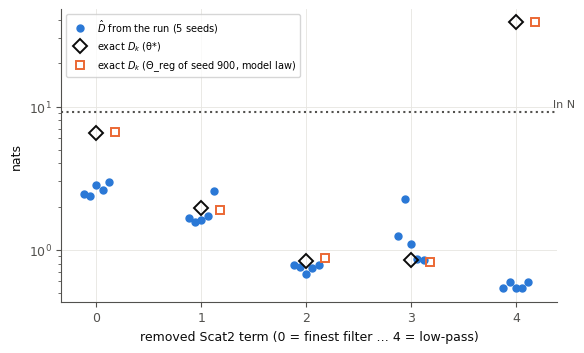

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
sg = cseed[(cseed.terms.str.len() == 1)].copy(); sg['term'] = sg.terms.astype(int)
ax.plot(sg.term + (sg.seed - 902) * 0.06, sg.Dhat, 'o', color=BLUE, ms=5, label=r'$\hat{D}$ from the run (5 seeds)')
l9 = c900[c900.n_terms == 1]
ax.plot(sg.groupby('term').D_star.first().index, sg.groupby('term').D_star.first().values, 'D', color=INK, ms=7, mfc='none', mew=1.4, label=r'exact $D_k$ (θ*)')
ax.plot(l9.terms.astype(int) + 0.18, l9.D_model, 's', color=ORANGE, ms=6, mfc='none', mew=1.4, label=r'exact $D_k$ (Θ_reg of seed 900, model law)')
ax.axhline(np.log(1e4), color=MUTED, ls=':'); ax.text(4.35, np.log(1e4) * 1.08, 'ln N', fontsize=8, color=MUTED)
ax.set_yscale('log'); ax.set_xticks(range(5)); ax.set_xlabel('removed Scat2 term (0 = finest filter … 4 = low-pass)'); ax.set_ylabel('nats')
ax.legend(fontsize=7, loc='upper left'); plt.show()

In [15]:
sd = cseed[cseed.terms.str.len() == 1].copy(); sd['term'] = sd.terms.astype(int)
sd['D̂ / exact'] = sd.Dhat / sd.D_star
sd[['seed', 'term', 'Dhat', 'D_star', 'D̂ / exact', 'ESS']].rename(columns={'Dhat': 'D̂', 'D_star': 'exact D_k (θ*)'}).round(3)

,seed,term,D̂,exact D_k (θ*),D̂ / exact,ESS
1,900,0,2.438,6.572,0.371,38.448
2,900,1,1.664,1.959,0.849,40.291
3,900,2,0.780,0.829,0.941,351.860
4,900,3,1.248,0.843,1.479,7.990
5,900,4,0.543,38.704,0.014,359.370
7,901,0,2.372,6.572,0.361,58.144
8,901,1,1.549,1.959,0.791,119.790
9,901,2,0.762,0.829,0.919,104.040
10,901,3,2.246,0.843,2.663,1.841
11,901,4,0.593,38.704,0.015,193.480


## 7. Sensitivity of the exact D_k to θ
**What:** the exact D_k of a term depends on how close z is to 1, and for the finest filter (term 0) and the low-pass (term 4) z ≈ 1 at θ*. Here θ* is perturbed 400 times by a random 2 % relative error (the size of the fit error), and D_k is recomputed: (a) with p kept equal to p*; (b) with p = the Gaussian law of the perturbed model itself.
**Takeaway:** with p fixed, D_k becomes infinite in 53 % of the draws for term 0 and 46 % for term 4; with p equal to the model's own law it is never infinite and stays at 6.6 and 38.7 nats (medians). Terms 1–3 move by up to about ±13 % (5–95 %: 1.8–2.2, 0.74–0.93, 0.75–0.95 nats). The exact D_k of terms 0 and 4 depends on the sampled spectrum at a level below the sampling noise.

In [16]:
csens.rename(columns={'D_star': 'exact D_k (θ*)', 'zmax_star': 'z at θ*', 'frac_inf_pfixed': 'share D=∞ (p fixed = p*)', 'D_pfixed_q05': 'D 5 %',
                      'D_pfixed_med': 'D median', 'D_pfixed_q95': 'D 95 %', 'frac_inf_model': 'share D=∞ (p = model law)',
                      'D_model_med': 'D median (model law)'})[['term', 'z at θ*', 'exact D_k (θ*)', 'share D=∞ (p fixed = p*)', 'D 5 %', 'D median', 'D 95 %',
                      'share D=∞ (p = model law)', 'D median (model law)']].round(3)

,term,z at θ*,exact D_k (θ*),share D=∞ (p fixed = p*),D 5 %,D median,D 95 %,share D=∞ (p = model law),D median (model law)
0,0,0.998,6.572,0.528,3.675,4.701,6.440,0,6.575
1,1,0.831,1.959,0.000,1.784,1.962,2.154,0,1.960
2,2,0.797,0.829,0.000,0.742,0.831,0.932,0,0.829
3,3,0.808,0.843,0.000,0.746,0.833,0.953,0,0.841
4,4,1.000,38.704,0.458,0.972,1.342,2.381,0,38.702


## 8. D_k against I_k (exact)
**What:** I_k is the entropy gained by the group after refitting the other Scat2 terms; it is exact here because p* is Gaussian and the Scat2 terms are quadratic (convex minimisation over the Scat2 coefficients; L₆ and Scat4 are not refit, their true weight is 0). It does not exist for groups that leave a Fourier mode without any term (the same 7 groups with D_k = ∞).
**Read:** points below the dashed line mean I_k < D_k.
**Takeaway:** I_k ≤ D_k in all 24 finite groups, as it must be. For the single terms the gap D_k − I_k is 1.4, 0.7, 0.2, 0.25 and 0.07 nats. A large D̂ would only be a lower bound of D_k and says nothing about I_k from above; here the large D_k of the low-pass term (38.7 nats) is also a large I_k (38.6 nats).

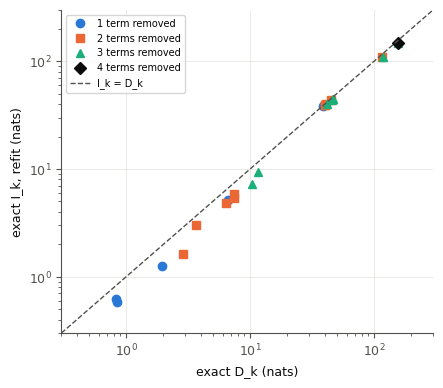

In [17]:
m = cIk[np.isfinite(cIk.I_k) & np.isfinite(cIk.D_star)].copy()
fig, ax = plt.subplots(figsize=(4.8, 4.2))
for n, mk, col in ((1, 'o', BLUE), (2, 's', ORANGE), (3, '^', AQUA), (4, 'D', INK)):
    g = m[m.n_terms == n]
    if len(g): ax.plot(g.D_star, g.I_k, mk, color=col, ms=6, label=f'{n} term' + ('s' if n > 1 else '') + ' removed')
lim = [0.3, 300]; ax.plot(lim, lim, color=MUTED, lw=1, ls='--', label='I_k = D_k')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('exact D_k (nats)'); ax.set_ylabel('exact I_k, refit (nats)'); ax.legend(fontsize=7, loc='upper left'); plt.show()

In [18]:
t8 = cIk[cIk.n_terms == 1][['terms', 'D_star', 'I_k']].rename(columns={'terms': 'term', 'D_star': 'exact D_k', 'I_k': 'exact I_k (refit)'})
t8['D_k − I_k'] = t8['exact D_k'] - t8['exact I_k (refit)']
print('groups with no finite refit (I_k = inf or no free term):', ', '.join(cIk[~np.isfinite(cIk.I_k)].terms))
print('I_k <= D_k in every finite group:', bool((m.I_k <= m.D_star + 1e-9).all()))
t8.round(3)

groups with no finite refit (I_k = inf or no free term): 012, 234, 0123, 0124, 0234, 1234, 01234
I_k <= D_k in every finite group: True


,term,exact D_k,exact I_k (refit),D_k − I_k
0,0,6.572,5.167,1.405
1,1,1.959,1.252,0.707
2,2,0.829,0.626,0.203
3,3,0.843,0.589,0.254
4,4,38.704,38.633,0.071


## 9. How many signals would we need?
**What:** the sample size needed is about exp(K), where K = KL(q_k ‖ p) is a second divergence (model with the group removed against the full model), computed exactly here. Our N = 10⁴ corresponds to ln N = 9.2 (dotted line).
**Read:** D̂ / exact D_k against K (the groups with K ≥ 10⁴ are not drawn, they are listed in the printed lines).
**Takeaway:** D̂ / exact D_k is 0.83–0.92 for the 4 groups with K < ln N, 0.37–0.55 for the 7 groups with ln N < K < 10⁴, and 0.02–0.08 for the 13 groups with K ≥ 10⁴ (all of them contain term 4, or both terms 0 and 1). The real-data families have ESS ≈ 1, which points to the same regime.

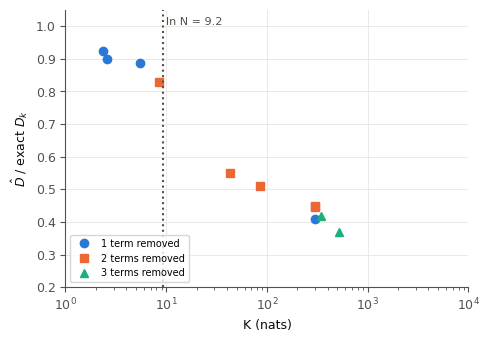

In [19]:
m = bench.merge(rkl[['terms', 'KL_q_p']], on='terms'); m = m[np.isfinite(m.D_exact) & np.isfinite(m.KL_q_p)].copy()
m['ratio'] = m.Dhat_mean / m.D_exact; m_all = m; m = m[m.KL_q_p < 1e4]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for n, mk, col in ((1, 'o', BLUE), (2, 's', ORANGE), (3, '^', AQUA)):
    g = m[m.n_terms == n]
    ax.plot(g.KL_q_p, g.ratio, mk, color=col, ms=6, label=f'{n} term' + ('s' if n > 1 else '') + ' removed')
ax.axvline(np.log(1e4), color=MUTED, ls=':'); ax.text(np.log(1e4) * 1.08, 1.03, 'ln N = 9.2', fontsize=8, color=MUTED, va='top')
ax.set_xscale('log'); ax.set_xlim(1, 1e4); ax.set_ylim(0.2, 1.05); ax.set_xlabel('K (nats)'); ax.set_ylabel(r'$\hat{D}$ / exact $D_k$'); ax.legend(fontsize=7, loc='lower left')
plt.show()

In [20]:
lnN = np.log(1e4)
for lab, sel in (('K < ln N', m_all.KL_q_p < lnN), ('ln N < K < 1e4', (m_all.KL_q_p >= lnN) & (m_all.KL_q_p < 1e4)), ('K >= 1e4 (not drawn)', m_all.KL_q_p >= 1e4)):
    r = m_all[sel].ratio
    print(f'{lab:22s}: {len(r):2d} groups, D̂ / exact D_k from {r.min():.3f} to {r.max():.3f}' if len(r) else f'{lab}: none')

K < ln N              :  4 groups, D̂ / exact D_k from 0.828 to 0.924
ln N < K < 1e4        :  7 groups, D̂ / exact D_k from 0.368 to 0.550
K >= 1e4 (not drawn)  : 13 groups, D̂ / exact D_k from 0.021 to 0.083


## 10. The smoothing parameter λ
**What:** the fit has a smoothing parameter λ. We tried 7 values (10⁻⁶ … 1) and measured the loss on other seeds' data (lower = better).
**Read:** how much worse each λ is than λ = 1.
**Takeaway:** the loss keeps falling but flattens (gain per decade 0.07 → 0.0001). λ = 1 wins, but 0.1 or 0.01 would give almost the same result.

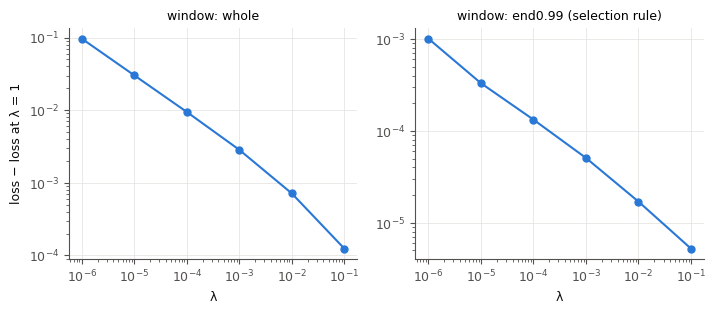

In [21]:
xs = torch.load(RUN / 'xseed_g4_M16.pt', map_location='cpu', weights_only=False)
lams = np.array(xs['lams'])
fig, axs = plt.subplots(1, 2, figsize=(8.2, 3.0))
for ax, wnd, title in zip(axs, ('whole', 'end0.99'), ('window: whole', 'window: end0.99 (selection rule)')):
    a = np.asarray(xs['loss'][wnd], float); mean = np.nanmean(a.reshape(-1, a.shape[-1]), axis=0)
    ax.loglog(lams[:-1], (mean - mean[-1])[:-1], 'o-', color=BLUE, ms=5); ax.set_xlabel('λ'); ax.set_title(title, fontsize=9)
axs[0].set_ylabel('loss − loss at λ = 1')
plt.show()

## Summary
1. The fitted model recovers the truth: entropy within 0.03 nats, θ within 2.5 % (section 2).
2. For the extra Scat4 groups D_k ≈ 0.001 nats, confirmed by an independent prediction (section 3). These are measured (ESS ≈ 10⁴).
3. For the Scat2 terms D̂ is biased low (on average over sets) and requiring k̂ < 0.5 (with the ESS and drift tests) flags it in this test (sections 4–6). The low-pass term (exact D_k = 38.7 nats, not ∞) is underestimated 70-fold.
4. The exact D_k of the terms with z ≈ 1 is not robust to a 2 % change of θ if p is held fixed (section 7).
5. D_k ≥ I_k exactly; a large D̂ is a lower bound on D_k and carries no upper information on I_k (section 8).
6. λ: a plateau, so the choice λ = 1 is not critical (section 10).